# Imports...

In [1]:
import pandas as pd # run this before anything!!!
import matplotlib.pyplot as plt # run this before anything!!!
import seaborn as sns # run this before anything!!!
from wordcloud import WordCloud

# BASICS

In [2]:
df = pd.read_csv("footballcapstone.csv")
df

,Player Name,Player Team,Team Formation,Player Age,Player Height,Position 1,Position 2,Mins Played,tacklePerGame,interceptionPerGame,...,totalPassesPerGame,passSuccess,accurateCrossesPerGame,accurateLongPassPerGame,accurateThroughBallPerGame,xG,xGPerNinety,totalShots,xGPerShot,rating
0,Lamine Yamal,Barcelona,4-2-3-1,17,180,AM(R),AM(R),1885,1.3,0.5,...,35.4,78.0,0.6,0.8,0.4,7.38,0.35,82,0.09,7.96
1,Mohamed Salah,Liverpool,4-2-3-1,32,175,AM(CLR),FW,2485,0.6,0.1,...,30.1,73.7,0.5,0.8,0.2,20.84,0.75,101,0.21,7.89
2,Harry Kane,Bayern,4-2-3-1,31,188,AM(C),FW,1738,0.3,0.1,...,20.4,81.1,0.2,1.4,0.5,18.32,0.95,82,0.22,7.86
3,Ousmane Dembélé,PSG,4-3-3,27,178,AM(CLR),FW,1373,0.5,0.4,...,34.5,83.7,1.3,1.1,0.2,13.08,0.86,73,0.18,7.85
4,Bukayo Saka,Arsenal,4-3-3,23,178,LB,M(CLR),1276,1.4,0.1,...,27.1,84.3,1.9,0.3,0.1,4.79,0.34,46,0.10,7.79
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1528,Brian Oliván,Espanyol,4-2-3-1,30,175,D(CL),D(CL),1017,0.8,0.6,...,19.4,75.4,0.8,1.4,0.0,0.24,0.02,6,0.04,6.34
1529,Koji Miyoshi,Bochum,3-5-2,27,167,M(CLR),M(CLR),449,0.6,0.1,...,8.4,62.4,0.0,0.1,0.1,1.13,0.23,12,0.09,6.07
1530,Samuele Vignato,Monza,3-5-2,21,172,AM(C),AM(C),414,0.5,0.0,...,9.8,80.5,0.0,0.2,0.1,0.26,0.06,3,0.09,6.04
1531,Enzo Loiodice,Las Palmas,4-2-3-1,24,177,DMC,DMC,498,0.7,0.3,...,20.5,85.4,0.2,0.6,0.0,0.13,0.02,4,0.03,6.04


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1533 entries, 0 to 1532
Data columns (total 32 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Player Name                 1533 non-null   str    
 1   Player Team                 1533 non-null   str    
 2   Team Formation              1533 non-null   str    
 3   Player Age                  1533 non-null   int64  
 4   Player Height               1533 non-null   int64  
 5   Position 1                  1533 non-null   str    
 6   Position 2                  1533 non-null   str    
 7   Mins Played                 1533 non-null   int64  
 8   tacklePerGame               1533 non-null   float64
 9   interceptionPerGame         1533 non-null   float64
 10  foulsPerGame                1533 non-null   float64
 11  clearancePerGame            1533 non-null   float64
 12  wasDribbledPerGame          1533 non-null   float64
 13  goal                        1533 non-null   

In [4]:
df.describe()

,Player Age,Player Height,Mins Played,tacklePerGame,interceptionPerGame,foulsPerGame,clearancePerGame,wasDribbledPerGame,goal,assistTotal,...,turnoverPerGame,totalPassesPerGame,passSuccess,accurateCrossesPerGame,accurateLongPassPerGame,accurateThroughBallPerGame,xG,totalShots,xGPerShot,rating
count,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,1533.000000,...,1533.000000,1529.000000,1529.000000,1529.000000,1529.000000,1529.000000,1533.000000,1533.000000,1533.000000,1533.000000
mean,26.490541,182.910633,1374.348989,1.133659,0.567776,0.797456,1.464449,0.502414,2.017613,1.417482,...,0.973907,29.971092,80.605167,0.293525,1.493264,0.045520,2.172844,17.287671,0.101820,6.629798
std,4.083105,6.679865,542.281833,0.697956,0.447992,0.448059,1.419602,0.329055,2.952687,1.741599,...,0.660582,16.269728,8.163320,0.397477,1.533782,0.078649,2.794384,16.118607,0.069287,0.281165
min,17.000000,163.000000,52.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,2.100000,39.700000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.030000
25%,23.000000,178.000000,952.000000,0.600000,0.200000,0.500000,0.400000,0.300000,0.000000,0.000000,...,0.500000,17.200000,76.000000,0.000000,0.500000,0.000000,0.440000,6.000000,0.050000,6.430000
50%,26.000000,183.000000,1388.000000,1.100000,0.500000,0.800000,0.900000,0.500000,1.000000,1.000000,...,0.800000,28.500000,82.000000,0.100000,1.000000,0.000000,1.240000,13.000000,0.090000,6.610000
75%,29.000000,188.000000,1808.000000,1.600000,0.900000,1.100000,2.000000,0.700000,3.000000,2.000000,...,1.300000,39.300000,86.600000,0.400000,2.000000,0.100000,2.740000,23.000000,0.140000,6.790000
max,41.000000,202.000000,2520.000000,3.800000,2.400000,2.700000,8.500000,1.900000,25.000000,17.000000,...,3.600000,106.900000,95.300000,2.700000,11.000000,0.600000,22.190000,106.000000,0.770000,7.960000


# Missing Data Analysis

In [5]:
missingvalues = df.isnull()
missingvalues

,Player Name,Player Team,Team Formation,Player Age,Player Height,Position 1,Position 2,Mins Played,tacklePerGame,interceptionPerGame,...,totalPassesPerGame,passSuccess,accurateCrossesPerGame,accurateLongPassPerGame,accurateThroughBallPerGame,xG,xGPerNinety,totalShots,xGPerShot,rating
0,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1528,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1529,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1530,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1531,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [6]:
missingvalues = df.isnull().sum()
missingvalues

Player Name                   0
Player Team                   0
Team Formation                0
Player Age                    0
Player Height                 0
Position 1                    0
Position 2                    0
Mins Played                   0
tacklePerGame                 0
interceptionPerGame           0
foulsPerGame                  0
clearancePerGame              0
wasDribbledPerGame            0
goal                          0
assistTotal                   0
shotsPerGame                  0
keyPassPerGame                0
dribbleWonPerGame             0
foulGivenPerGame              0
offsideGivenPerGame           0
dispossessedPerGame           0
turnoverPerGame               0
totalPassesPerGame            4
passSuccess                   4
accurateCrossesPerGame        4
accurateLongPassPerGame       4
accurateThroughBallPerGame    4
xG                            0
xGPerNinety                   0
totalShots                    0
xGPerShot                     0
rating  

In [7]:
missingdatapercent =  missingvalues/(len(df))*100
missingdatapercent

Player Name                   0.000000
Player Team                   0.000000
Team Formation                0.000000
Player Age                    0.000000
Player Height                 0.000000
Position 1                    0.000000
Position 2                    0.000000
Mins Played                   0.000000
tacklePerGame                 0.000000
interceptionPerGame           0.000000
foulsPerGame                  0.000000
clearancePerGame              0.000000
wasDribbledPerGame            0.000000
goal                          0.000000
assistTotal                   0.000000
shotsPerGame                  0.000000
keyPassPerGame                0.000000
dribbleWonPerGame             0.000000
foulGivenPerGame              0.000000
offsideGivenPerGame           0.000000
dispossessedPerGame           0.000000
turnoverPerGame               0.000000
totalPassesPerGame            0.260926
passSuccess                   0.260926
accurateCrossesPerGame        0.260926
accurateLongPassPerGame  

A small amount of data is missing; however, the proportion is negligible and is unlikely to significantly affect the results of my analysis.

# FILTERING

## How many players in the dataset have scored at least one goal?

In [8]:
goalscorers = df[df["goal"]>0][["Player Name", "Player Team", "goal"]].sort_values(by = "goal", ascending = False)
goalscorers

,Player Name,Player Team,goal
1,Mohamed Salah,Liverpool,25
2,Harry Kane,Bayern,21
24,Robert Lewandowski,Barcelona,21
33,Mateo Retegui,Atalanta,21
15,Erling Haaland,Man City,20
...,...,...,...
1004,Pepelu,Valencia,1
1001,Marcos André,Real Valladolid,1
468,Joseph Okumu,Reims,1
996,Rico Lewis,Man City,1


## Which players have played enough minutes for their goal-scoring performance to be more meaningfully compared?


In [9]:
regular_players = df[df["Mins Played"]>=1000][["Player Name", "Player Team", "goal", "Mins Played", "Position 1"]].sort_values(by = "Mins Played", ascending = False)
regular_players


,Player Name,Player Team,goal,Mins Played,Position 1
80,Virgil van Dijk,Liverpool,1,2520,D(C)
1,Mohamed Salah,Liverpool,25,2485,AM(CLR)
1191,Emiliano Martínez,Aston Villa,0,2432,GK
990,André Onana,Man Utd,0,2430,GK
613,Wladimiro Falcone,Lecce,0,2430,GK
...,...,...,...,...,...
1301,Caleb Okoli,Leicester,0,1004,D(C)
279,Castello Lukeba,RBL,0,1003,D(C)
1371,Juan Cruz,Osasuna,4,1002,D(CL)
725,Martín Payero,Udinese,1,1002,AM(C)


 ## Players who scored at least one goal and played 1000 minutes...

In [10]:
filtered_df = df[(df["goal"]>0) & (df["Mins Played"]>=1000)][["Player Name", "Player Team", "goal", "Mins Played", "Position 1"]]

In [11]:
filtered_df

,Player Name,Player Team,goal,Mins Played,Position 1
0,Lamine Yamal,Barcelona,5,1885,AM(R)
1,Mohamed Salah,Liverpool,25,2485,AM(CLR)
2,Harry Kane,Bayern,21,1738,AM(C)
3,Ousmane Dembélé,PSG,18,1373,AM(CLR)
4,Bukayo Saka,Arsenal,5,1276,LB
...,...,...,...,...,...
1501,Raphaël Guerreiro,Bayern,1,1163,D(LR)
1502,Cameron Archer,Southampton,2,1130,FW
1506,Unai López,Rayo Vallecano,3,1130,M(CR)
1509,Marius Bülter,Hoffenheim,4,1113,RB


# POSITION EXPLANATION

## 1. Attack ⚽

| Code | Full Form |
|---|---|
| `AM(R)` | Attacking Midfielder (Right) |
| `AM(CLR)` | Attacking Midfielder (Centre, Left, Right) |
| `AM(C)` | Attacking Midfielder (Centre) |
| `AM(L)` | Attacking Midfielder (Left) |
| `AM(CR)` | Attacking Midfielder (Centre, Right) |
| `AM(LR)` | Attacking Midfielder (Left, Right) |
| `AM(CL)` | Attacking Midfielder (Centre, Left) |
| `FW` | Forward |

## 2. Midfield 🟡

| Code | Full Form |
|---|---|
| `M(CLR)` | Midfielder (Centre, Left, Right) |
| `M(LR)` | Midfielder (Left, Right) |
| `M(CR)` | Midfielder (Centre, Right) |
| `M(CL)` | Midfielder (Centre, Left) |
| `M(C)` | Midfielder (Centre) |
| `M(L)` | Midfielder (Left) |
| `M(R)` | Midfielder (Right) |
| `DMC` | Defensive Midfielder (Centre) |

## 3. Defense 🛡️

| Code | Full Form |
|---|---|
| `LB` | Left Back |
| `D(LR)` | Defender (Left, Right) |
| `D(CR)` | Defender (Centre, Right) |
| `RB` | Right Back |
| `D(C)` | Defender (Centre) |
| `D(CLR)` | Defender (Centre, Left, Right) |
| `D(CL)` | Defender (Centre, Left) |

## 4. Goalkeeper 🧤

| Code | Full Form |
|---|---|
| `GK` | Goalkeeper |

### Abbreviations

- `AM` = Attacking Midfielder
- `M` = Midfielder
- `D` = Defender
- `FW` = Forward
- `GK` = Goalkeeper
- `DM` = Defensive Midfielder
- `C` = Centre
- `L` = Left
- `R` = Right

In [12]:
forwards = df[df["Position 1"] == "FW"]

In [13]:
forwards

,Player Name,Player Team,Team Formation,Player Age,Player Height,Position 1,Position 2,Mins Played,tacklePerGame,interceptionPerGame,...,totalPassesPerGame,passSuccess,accurateCrossesPerGame,accurateLongPassPerGame,accurateThroughBallPerGame,xG,xGPerNinety,totalShots,xGPerShot,rating
13,Tim Kleindienst,Borussia M.Gladbach,4-2-3-1,29,194,FW,FW,2028,0.9,0.4,...,23.8,63.0,0.0,0.4,0.2,13.97,0.62,64,0.22,7.45
15,Erling Haaland,Man City,4-2-3-1,24,195,FW,FW,2304,0.3,0.2,...,11.8,65.3,0.0,0.1,0.0,20.79,0.81,97,0.21,7.42
17,Hugo Ekitiké,Eintracht Frankfurt,3-4-2-1,22,190,FW,FW,1774,0.6,0.3,...,18.0,78.3,0.3,0.5,0.0,16.78,0.85,83,0.20,7.40
24,Robert Lewandowski,Barcelona,4-2-3-1,36,185,FW,FW,2017,0.3,0.1,...,16.2,75.2,0.0,0.4,0.0,22.19,0.99,87,0.26,7.34
33,Mateo Retegui,Atalanta,3-4-2-1,25,186,FW,FW,1546,0.4,0.1,...,14.9,79.6,0.1,0.4,0.0,14.41,0.84,70,0.21,7.26
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1497,George Hirst,Ipswich,4-2-3-1,26,191,FW,FW,242,0.1,0.1,...,3.7,55.4,0.0,0.0,0.0,1.20,0.45,5,0.24,6.16
1502,Cameron Archer,Southampton,3-4-3,23,175,FW,FW,1130,0.4,0.1,...,7.8,81.8,0.0,0.1,0.1,5.46,0.43,25,0.22,6.15
1513,Juanmi Latasa,Real Valladolid,4-1-4-1,23,192,FW,FW,653,0.1,0.0,...,7.1,57.5,0.1,0.1,0.0,2.17,0.3,20,0.11,6.13
1524,Taiwo Awoniyi,Nottingham Forest,4-2-3-1,27,183,FW,FW,253,0.2,0.0,...,3.2,65.6,0.0,0.0,0.0,2.27,0.81,9,0.25,6.08


## Creating A Column... Goals_per_90

In [14]:
filtered_df = filtered_df.copy()

filtered_df["Goals_per_90"] = (
    filtered_df["goal"] / filtered_df["Mins Played"]
) * 90

print(
    filtered_df[
        ["Player Name", "goal", "Mins Played", "Goals_per_90"]
    ].head(10)
)

       Player Name  goal  Mins Played  Goals_per_90
0     Lamine Yamal     5         1885      0.238727
1    Mohamed Salah    25         2485      0.905433
2       Harry Kane    21         1738      1.087457
3  Ousmane Dembélé    18         1373      1.179898
4      Bukayo Saka     5         1276      0.352665
5         Raphinha    13         2135      0.548009
6    Florian Wirtz     9         1868      0.433619
7    Jamal Musiala    11         1558      0.635430
8    Kylian Mbappé    17         2080      0.735577
9    Michael Olise     8         1558      0.462131


## This is the actual amount of goals scored per 90mins played, not the expected amount of goals.

### This is important because total goals alone do not tell us how efficiently a player scores.

## Before continuing, we need to compare the dataset before and after filtering.

In [15]:
print("Original number of players:", len(df))
print("Filtered number of players:", len(filtered_df))

print("Minimum minutes:", filtered_df["Mins Played"].min())
print("Minimum goals:", filtered_df["goal"].min())


Original number of players: 1533
Filtered number of players: 692
Minimum minutes: 1001
Minimum goals: 1


# VISUALIZING

## Visualize the top scorers and how much they have scored

In [16]:
topscorers = goalscorers[["Player Name", "goal"]].head(15)

Text(0.5, 0, 'Player Name')

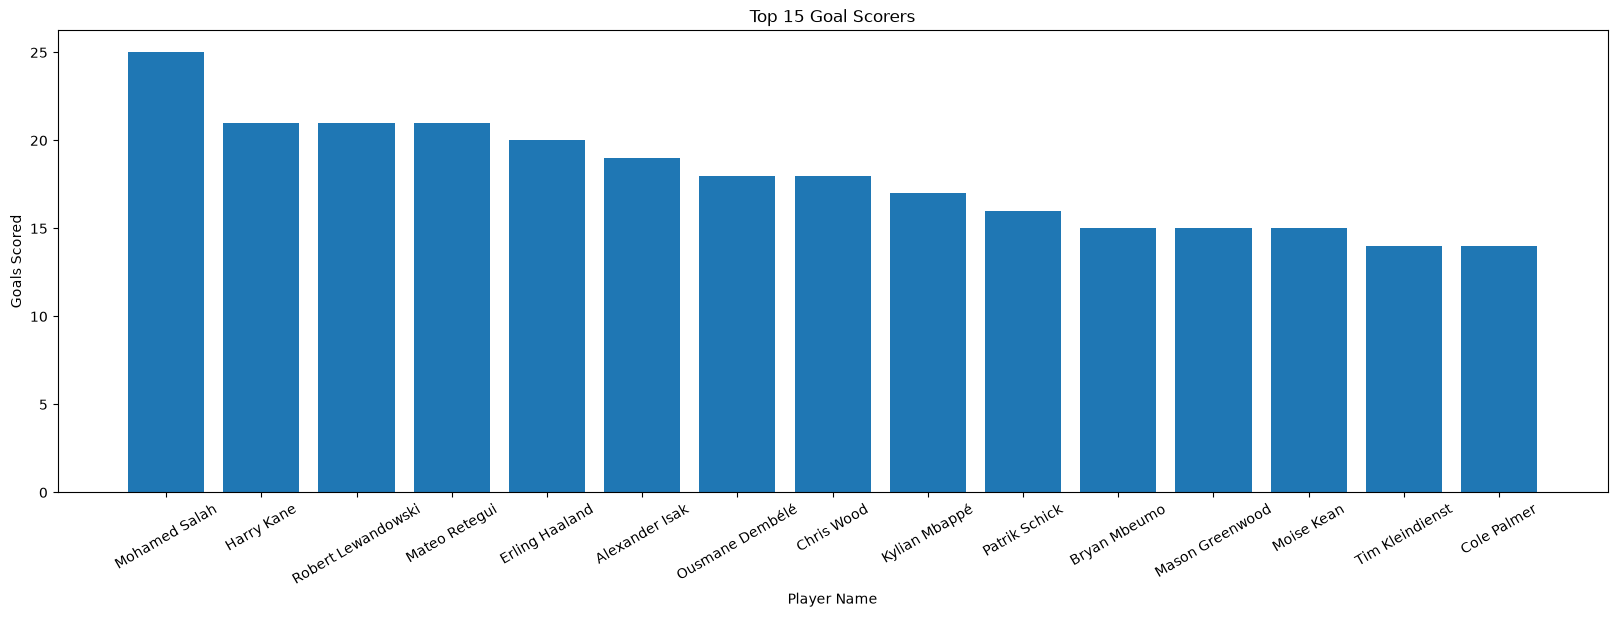

In [17]:
plt.figure(figsize = (20, 6))
plt.bar(topscorers["Player Name"], topscorers["goal"])
plt.xticks(rotation = 30)
plt.title("Top 15 Goal Scorers")
plt.ylabel("Goals Scored")
plt.xlabel("Player Name")

## Does Playing Time Matter? (Mins vs Goals)

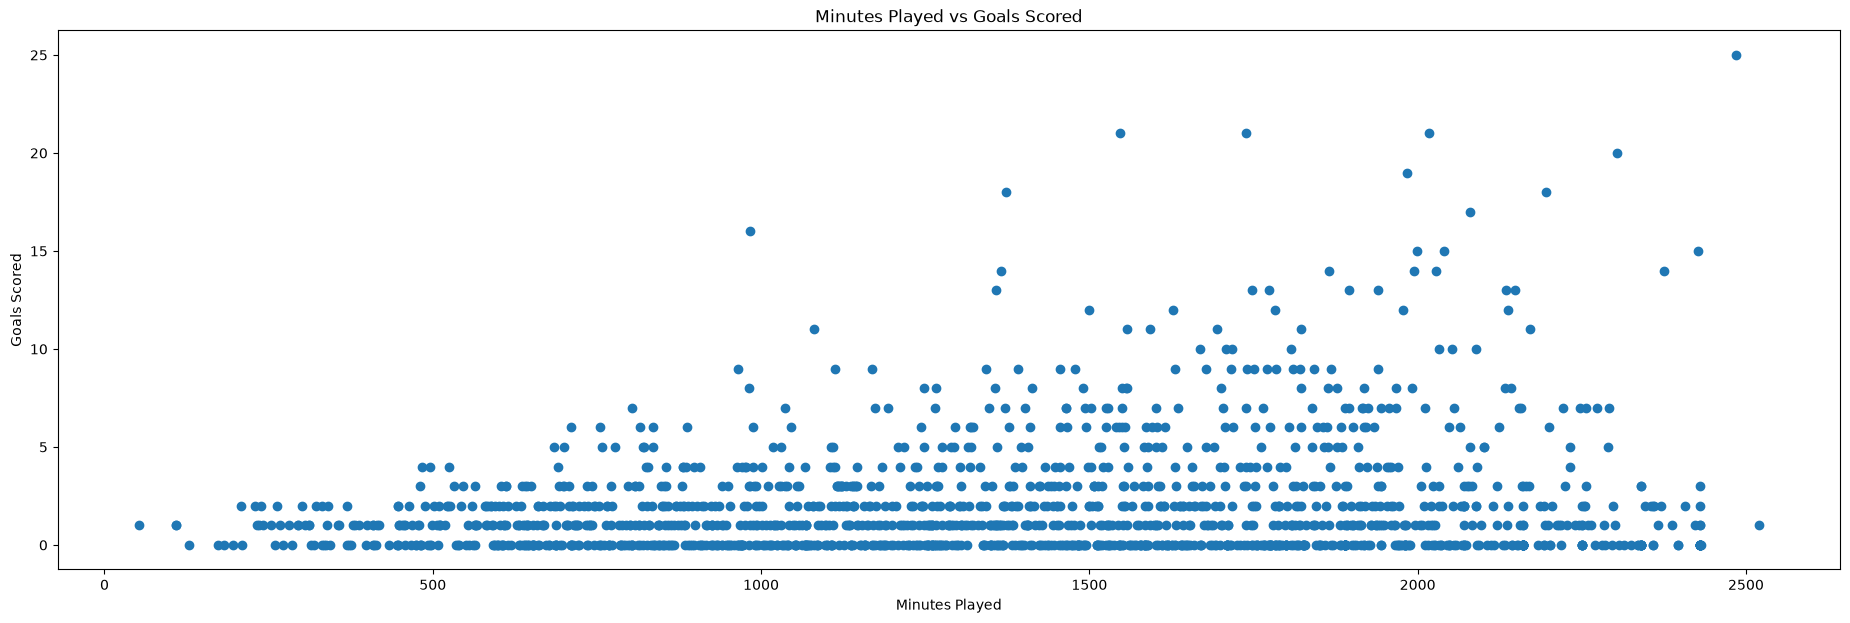

In [18]:
plt.figure(figsize=(23, 7))

plt.scatter(df["Mins Played"], df["goal"])

plt.xlabel("Minutes Played")
plt.ylabel("Goals Scored")
plt.title("Minutes Played vs Goals Scored")

plt.show()

##### If players with more minutes generally score more goals, playing time may be one factor associated with total goals.

## Does Height Matter?

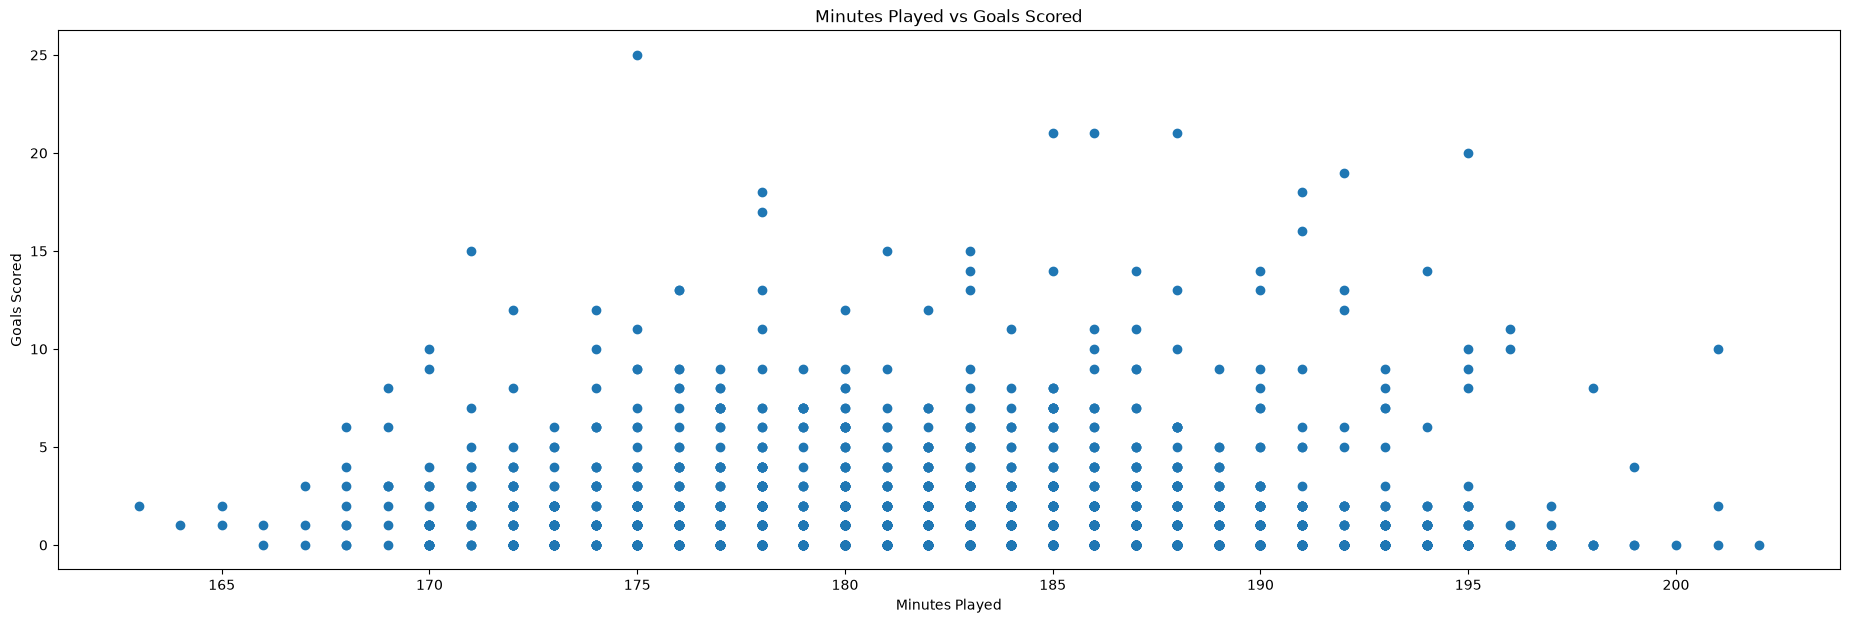

In [19]:
plt.figure(figsize=(23, 7))

plt.scatter(df["Player Height"], df["goal"])

plt.xlabel("Minutes Played")
plt.ylabel("Goals Scored")
plt.title("Minutes Played vs Goals Scored")

plt.show()

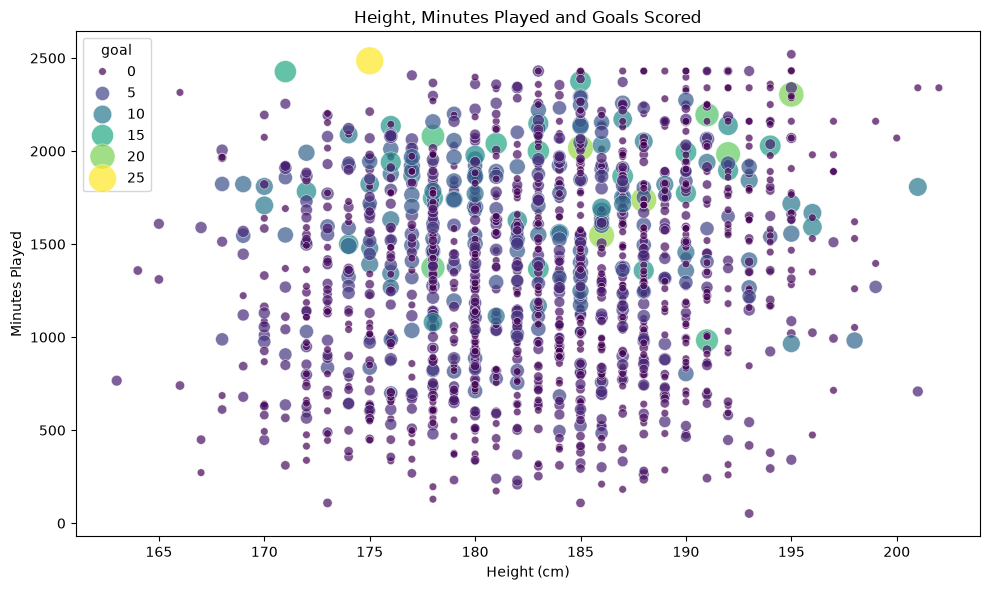

In [20]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Player Height",
    y="Mins Played",
    hue="goal",
    size="goal",
    sizes=(30, 400),
    palette="viridis",
    alpha=0.7
)

plt.title("Height, Minutes Played and Goals Scored")
plt.xlabel("Height (cm)")
plt.ylabel("Minutes Played")

plt.tight_layout()
plt.show()

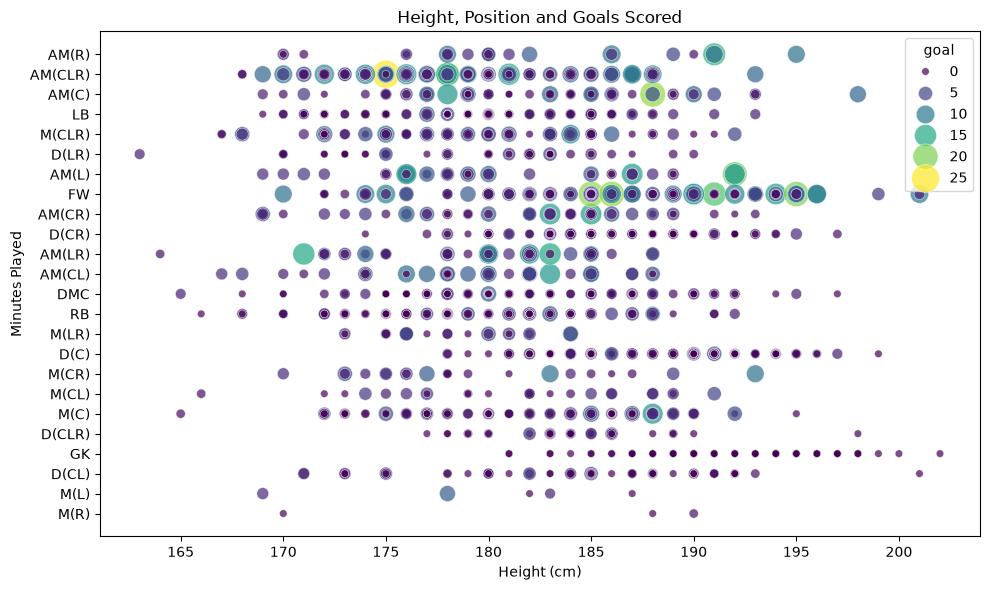

In [21]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Player Height",
    y="Position 1",
    hue="goal",
    size="goal",
    sizes=(30, 400),
    palette="viridis",
    alpha=0.7
)

plt.title("Height, Position and Goals Scored")
plt.xlabel("Height (cm)")
plt.ylabel("Minutes Played")

plt.tight_layout()
plt.show()

#### I conclude that height does not matter much when scoring goals. In my dataset, players taller than 200 cm scored fewer goals than players 175 cm tall. This suggests that skills and playing position may be more important than height.

## Making A New Column --> Position_Group

In [22]:
def group_position(position):

    if position in ["AM(R)", "AM(CLR)", "AM(C)", "AM(L)",
    "AM(CR)", "AM(LR)", "AM(CL)", "FW"]:
        return "Forward"

    elif position in [
    "M(CLR)", "M(LR)", "M(CR)", "M(CL)",
    "M(C)", "M(L)", "M(R)", "DMC"
]:
        return "Midfielder"

    elif position in ["LB", "D(LR)", "D(CR)", "RB",
    "D(C)", "D(CLR)", "D(CL)", "GK"]:
        return "Defender"



df["Position_Group"] = df["Position 1"].apply(group_position)

print(df["Position_Group"].value_counts())


Position_Group
Defender      699
Forward       455
Midfielder    379
Name: count, dtype: int64


## PairPlot on Position_Group

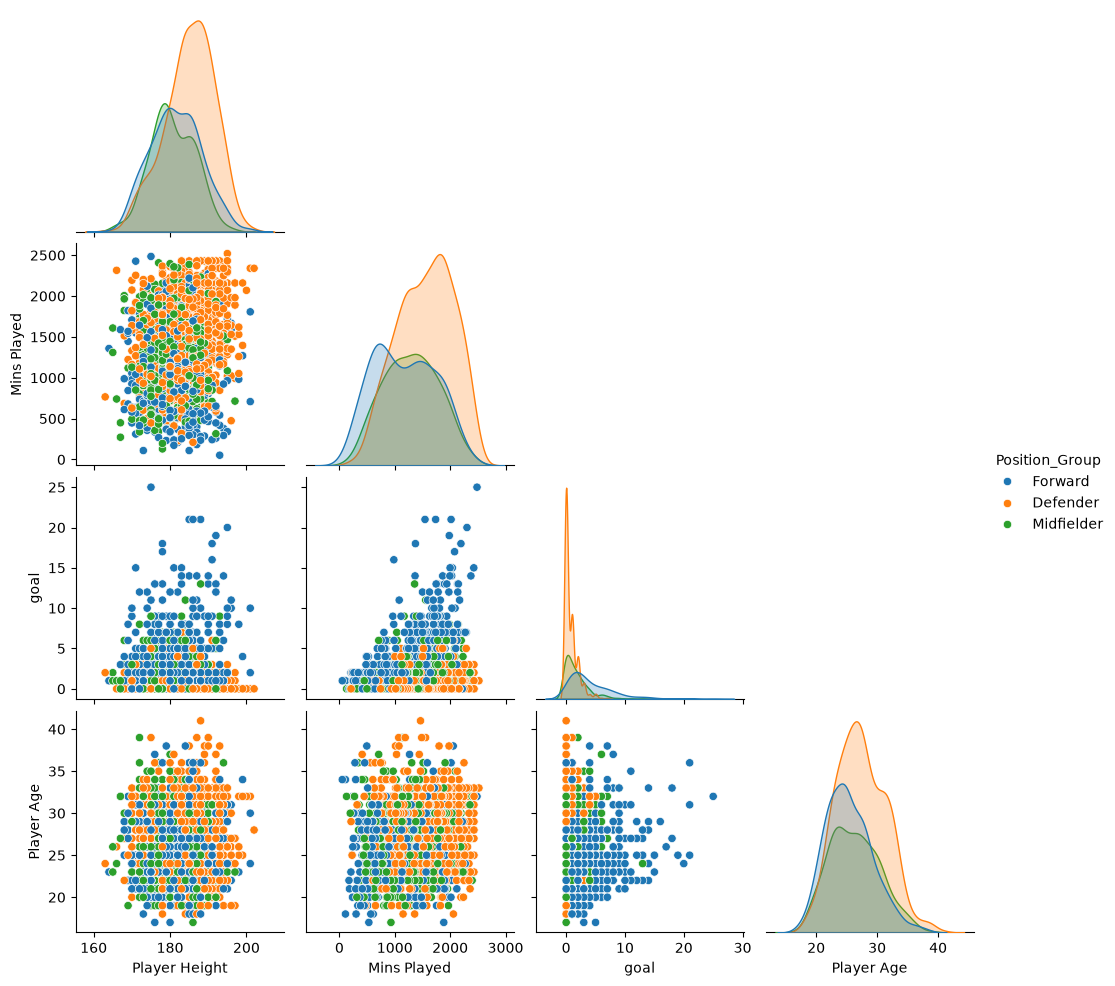

In [23]:
sns.pairplot(
    data=df,
    vars=["Player Height", "Mins Played", "goal", "Player Age"],
    hue="Position_Group",
    corner=True,
)

plt.show()

## Correlation Heatmap of Football Player Statistics

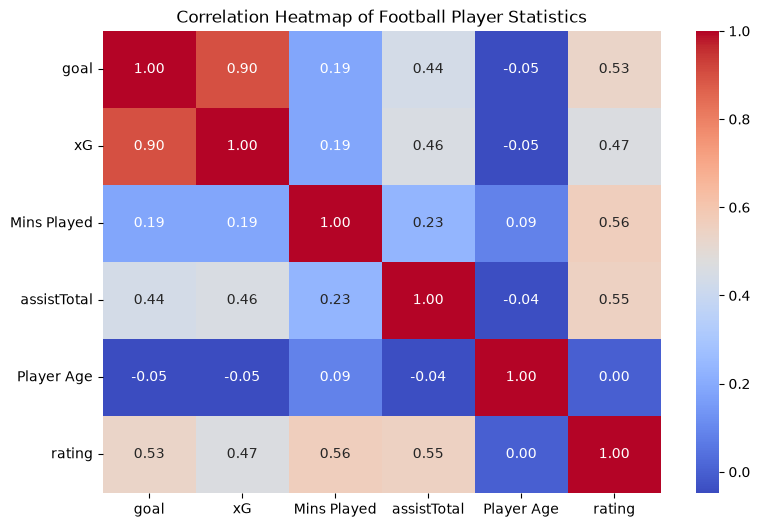

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

columns = ["goal", "xG", "Mins Played", "assistTotal", "Player Age", "rating"]

correlation = df[columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Football Player Statistics")
plt.show()

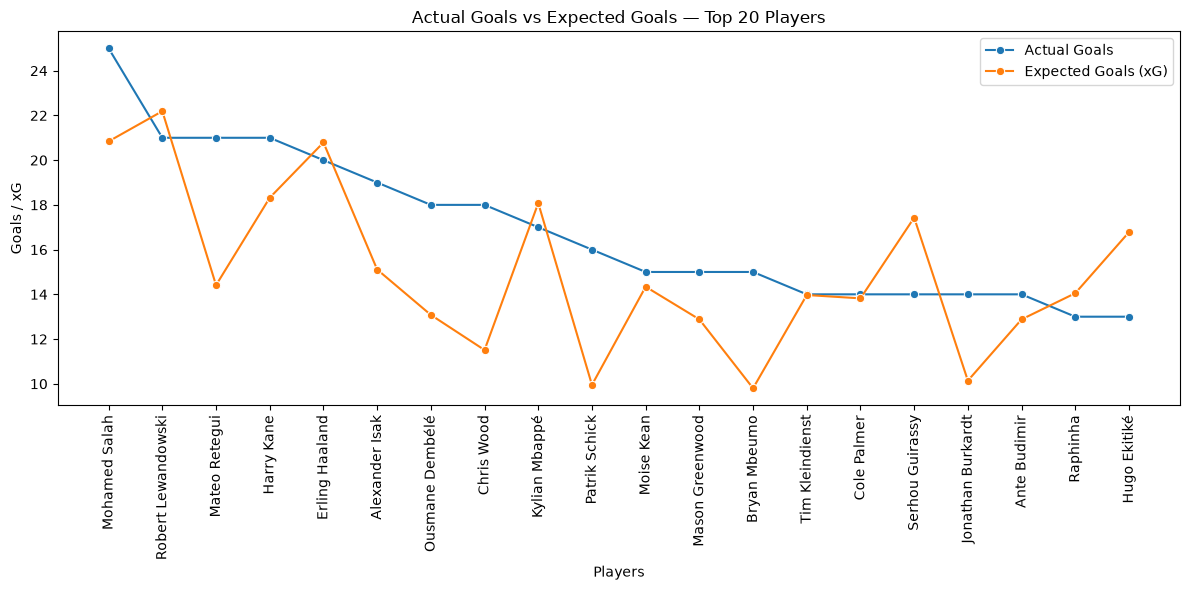

In [25]:
# Select the top 20 players by actual goals
top_20 = df.nlargest(20, "goal").copy()

# Sort by goals
top_20 = top_20.sort_values(by="goal", ascending=False)

plt.figure(figsize=(12, 6))

sns.lineplot(data=top_20, x="Player Name", y="goal", marker="o", label="Actual Goals")
sns.lineplot(data=top_20, x="Player Name", y="xG", marker="o", label="Expected Goals (xG)")

plt.title("Actual Goals vs Expected Goals — Top 20 Players")
plt.xlabel("Players")
plt.ylabel("Goals / xG")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

#### Some players surpassed their expectations.

## Calculating all goals by Position_Group

In [26]:
totalgoalsbypos = df.groupby("Position_Group")["goal"].sum()
totalgoalsbypos

Position_Group
Defender       527
Forward       1926
Midfielder     640
Name: goal, dtype: int64

## Goals By Position

Text(0.5, 1.0, 'Positions vs Goals')

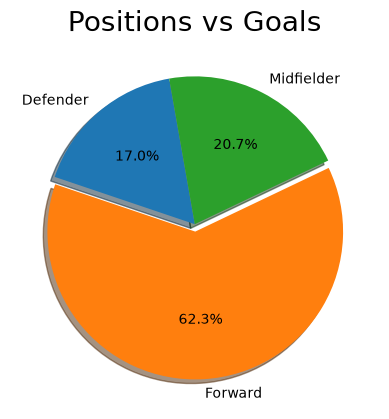

In [27]:
plt.pie(totalgoalsbypos, labels = totalgoalsbypos.index, autopct = "%1.1f%%", startangle = 100, shadow = True, explode = [0, 0.05, 0])
plt.title("Positions vs Goals", fontsize = 20)


## Creating a new column --> Goal_Per_Shot

In [28]:
df["Goal_Per_Shot"] = df["goal"] / df["totalShots"]
df

,Player Name,Player Team,Team Formation,Player Age,Player Height,Position 1,Position 2,Mins Played,tacklePerGame,interceptionPerGame,...,accurateCrossesPerGame,accurateLongPassPerGame,accurateThroughBallPerGame,xG,xGPerNinety,totalShots,xGPerShot,rating,Position_Group,Goal_Per_Shot
0,Lamine Yamal,Barcelona,4-2-3-1,17,180,AM(R),AM(R),1885,1.3,0.5,...,0.6,0.8,0.4,7.38,0.35,82,0.09,7.96,Forward,0.060976
1,Mohamed Salah,Liverpool,4-2-3-1,32,175,AM(CLR),FW,2485,0.6,0.1,...,0.5,0.8,0.2,20.84,0.75,101,0.21,7.89,Forward,0.247525
2,Harry Kane,Bayern,4-2-3-1,31,188,AM(C),FW,1738,0.3,0.1,...,0.2,1.4,0.5,18.32,0.95,82,0.22,7.86,Forward,0.256098
3,Ousmane Dembélé,PSG,4-3-3,27,178,AM(CLR),FW,1373,0.5,0.4,...,1.3,1.1,0.2,13.08,0.86,73,0.18,7.85,Forward,0.246575
4,Bukayo Saka,Arsenal,4-3-3,23,178,LB,M(CLR),1276,1.4,0.1,...,1.9,0.3,0.1,4.79,0.34,46,0.10,7.79,Defender,0.108696
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1528,Brian Oliván,Espanyol,4-2-3-1,30,175,D(CL),D(CL),1017,0.8,0.6,...,0.8,1.4,0.0,0.24,0.02,6,0.04,6.34,Defender,0.000000
1529,Koji Miyoshi,Bochum,3-5-2,27,167,M(CLR),M(CLR),449,0.6,0.1,...,0.0,0.1,0.1,1.13,0.23,12,0.09,6.07,Midfielder,0.083333
1530,Samuele Vignato,Monza,3-5-2,21,172,AM(C),AM(C),414,0.5,0.0,...,0.0,0.2,0.1,0.26,0.06,3,0.09,6.04,Forward,0.000000
1531,Enzo Loiodice,Las Palmas,4-2-3-1,24,177,DMC,DMC,498,0.7,0.3,...,0.2,0.6,0.0,0.13,0.02,4,0.03,6.04,Midfielder,0.000000


## Goal Chance per Shot VS xG chance per shot 

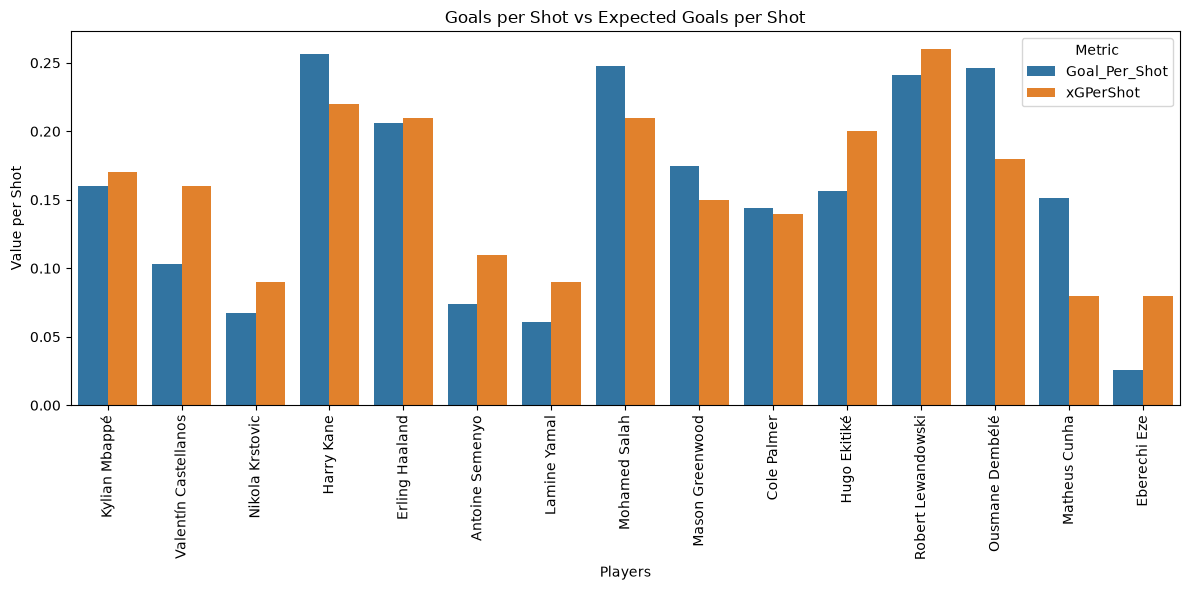

In [29]:

# Select top 15 players by number of shots
top_players = df.nlargest(15, "shotsPerGame").copy()

chart_data = top_players.melt(
    id_vars="Player Name",
    value_vars=["Goal_Per_Shot", "xGPerShot"],
    var_name="Metric",
    value_name="Value"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=chart_data,
    x="Player Name",
    y="Value",
    hue="Metric"
)

plt.title("Goals per Shot vs Expected Goals per Shot")
plt.xlabel("Players")
plt.ylabel("Value per Shot")
plt.xticks(rotation=90)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

# WORDCLOUD!


In [30]:
data = """football football football
goal goal goal goal
Messi Messi Messi
Ronaldo Ronaldo Ronaldo
striker striker striker
Premier League Premier League
Champions League Champions League
World Cup World Cup World Cup
passing passing passing
dribbling dribbling
shooting shooting shooting
defender defender
midfielder midfielder
goalkeeper goalkeeper
penalty penalty penalty
assist assist
tackle tackle
speed speed
teamwork teamwork teamwork
tactics tactics
Barcelona Barcelona
Real Madrid Real Madrid
Manchester United Manchester United
Brazil Brazil
Argentina Argentina
Mbappe Mbappe
Haaland Haaland
Neymar Neymar
xG xG xG
goals goals goals
footballer footballer
transfer transfer
trophy trophy
stadium stadium
fans fans
freekick freekick
header header
offside offside
defence defence
attack attack attack
victory victory
champion champion"""

(np.float64(-0.5), np.float64(999.5), np.float64(599.5), np.float64(-0.5))

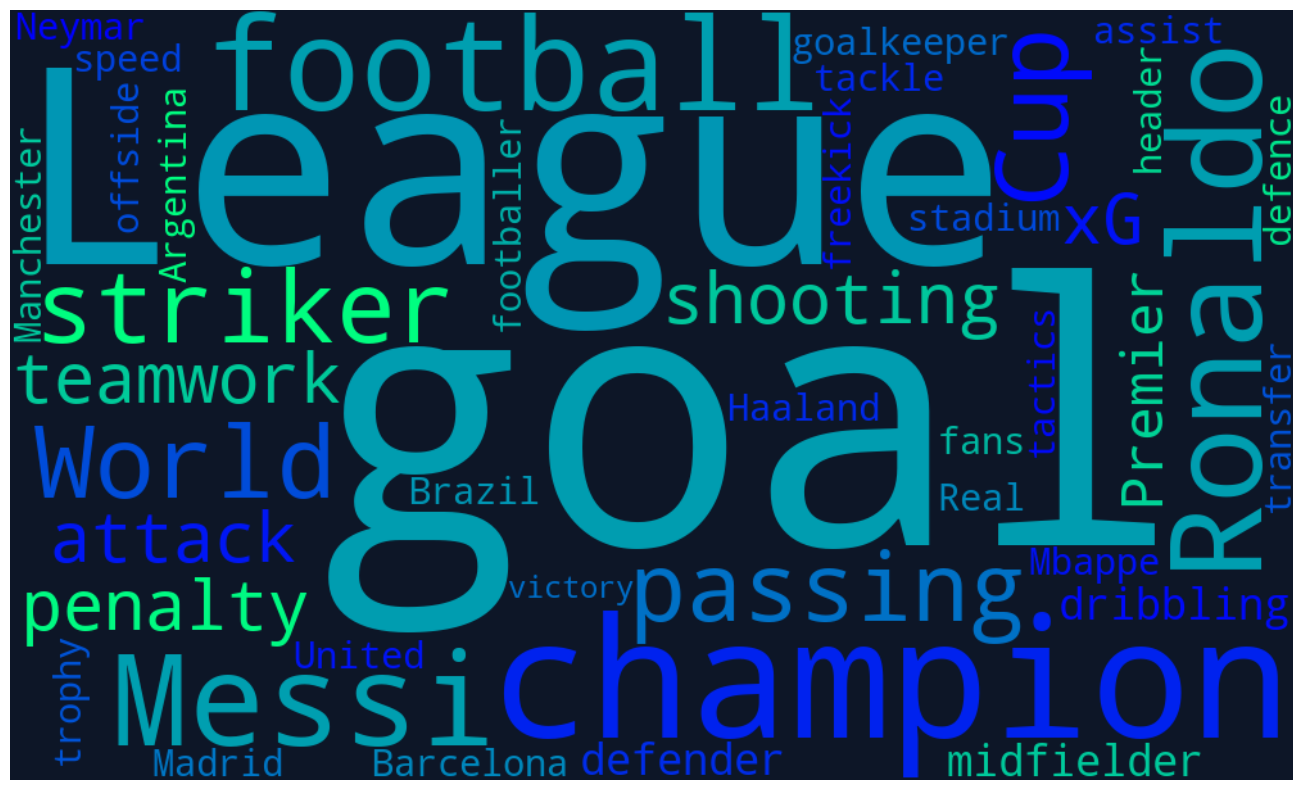

In [31]:
wordcloud = WordCloud(
    width=1000,
    height=600,
    background_color="#0d1627",
    colormap="winter").generate(data)
plt.figure(figsize = (20,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

In [32]:
data1 = "".join(df["Player Name"].astype(str))

(np.float64(-0.5), np.float64(999.5), np.float64(599.5), np.float64(-0.5))

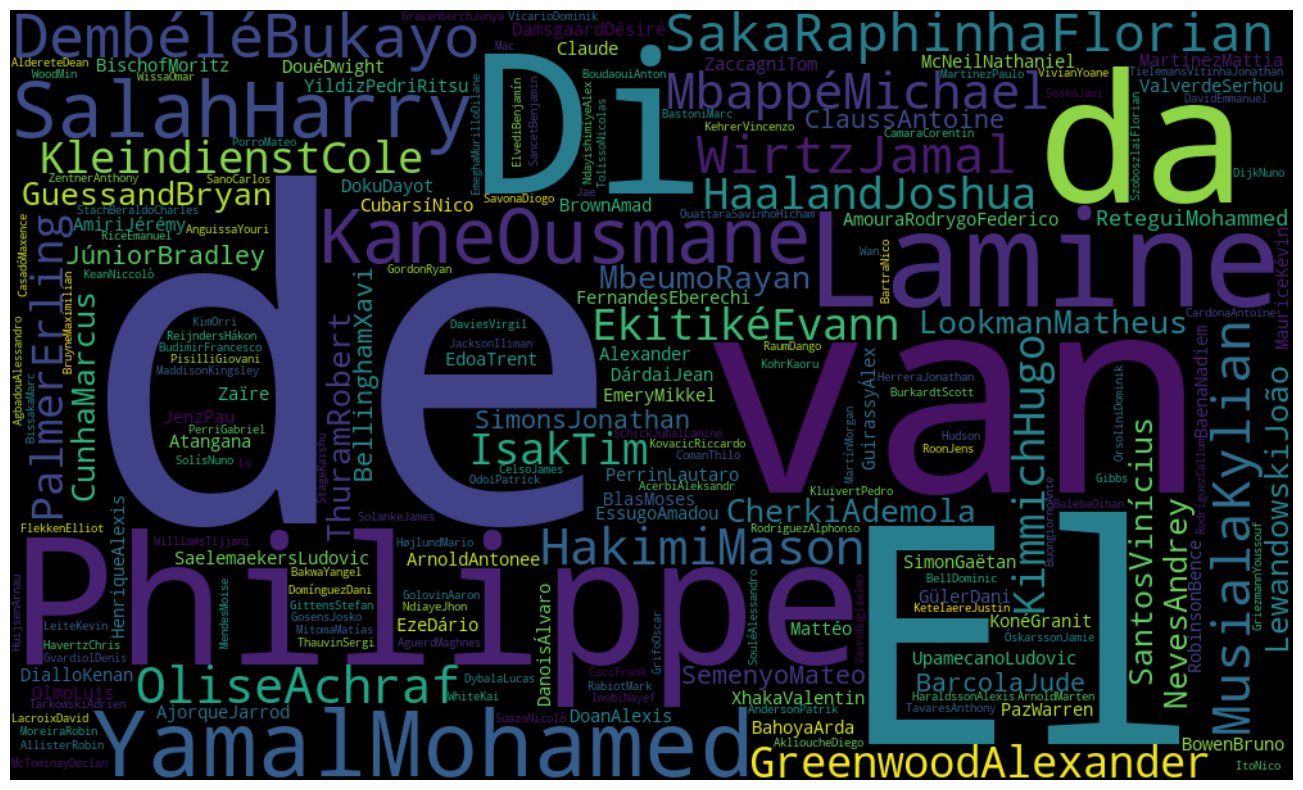

In [33]:
wordcloud = WordCloud(
    width=1000,
    height=600
    #,background_color="#0d1627",
    #colormap="winter"
).generate(data1)
plt.figure(figsize = (20,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

(np.float64(-0.5), np.float64(999.5), np.float64(599.5), np.float64(-0.5))

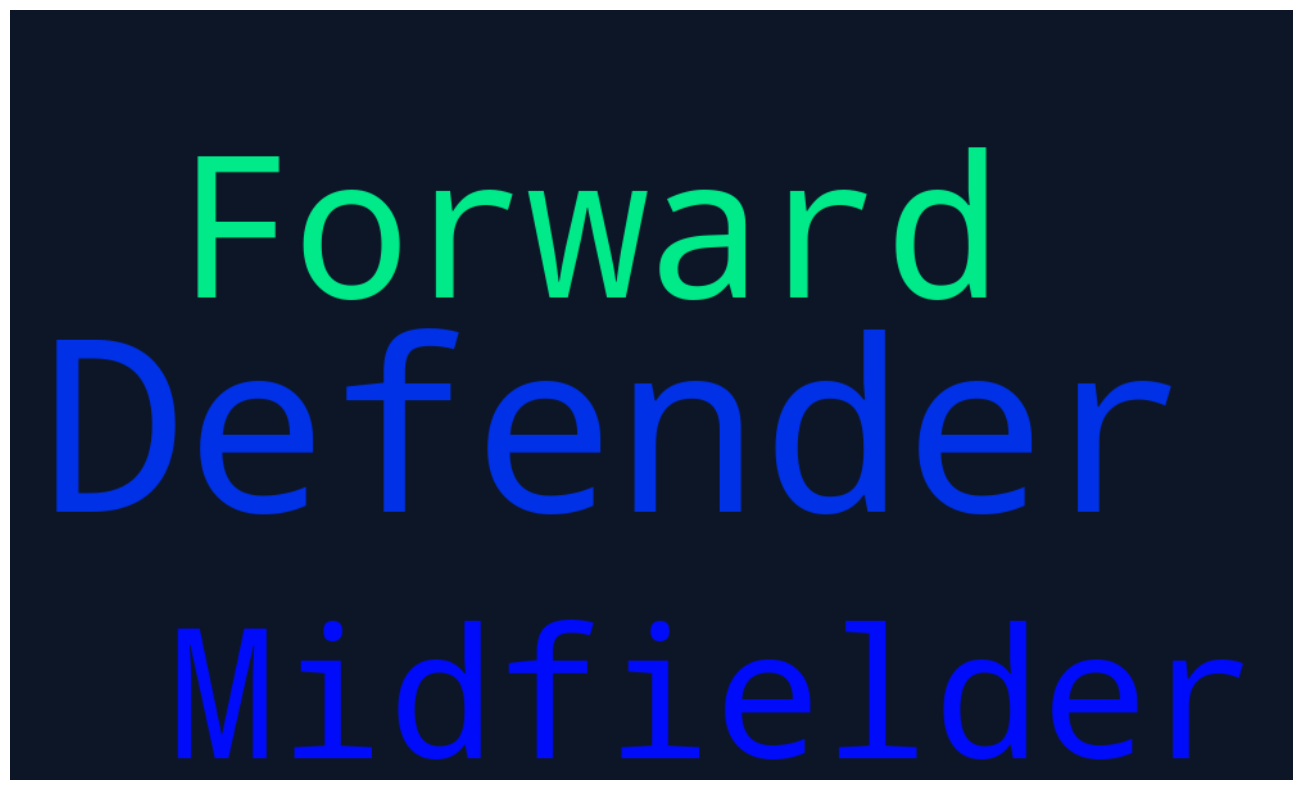

In [34]:
data2 = ",".join(df["Position_Group"].astype(str))

wordcloud = WordCloud(
    width=1000,
    height=600
    ,background_color="#0d1627",
    colormap="winter"
).generate(data2)
plt.figure(figsize = (20,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")

(np.float64(-0.5), np.float64(999.5), np.float64(599.5), np.float64(-0.5))

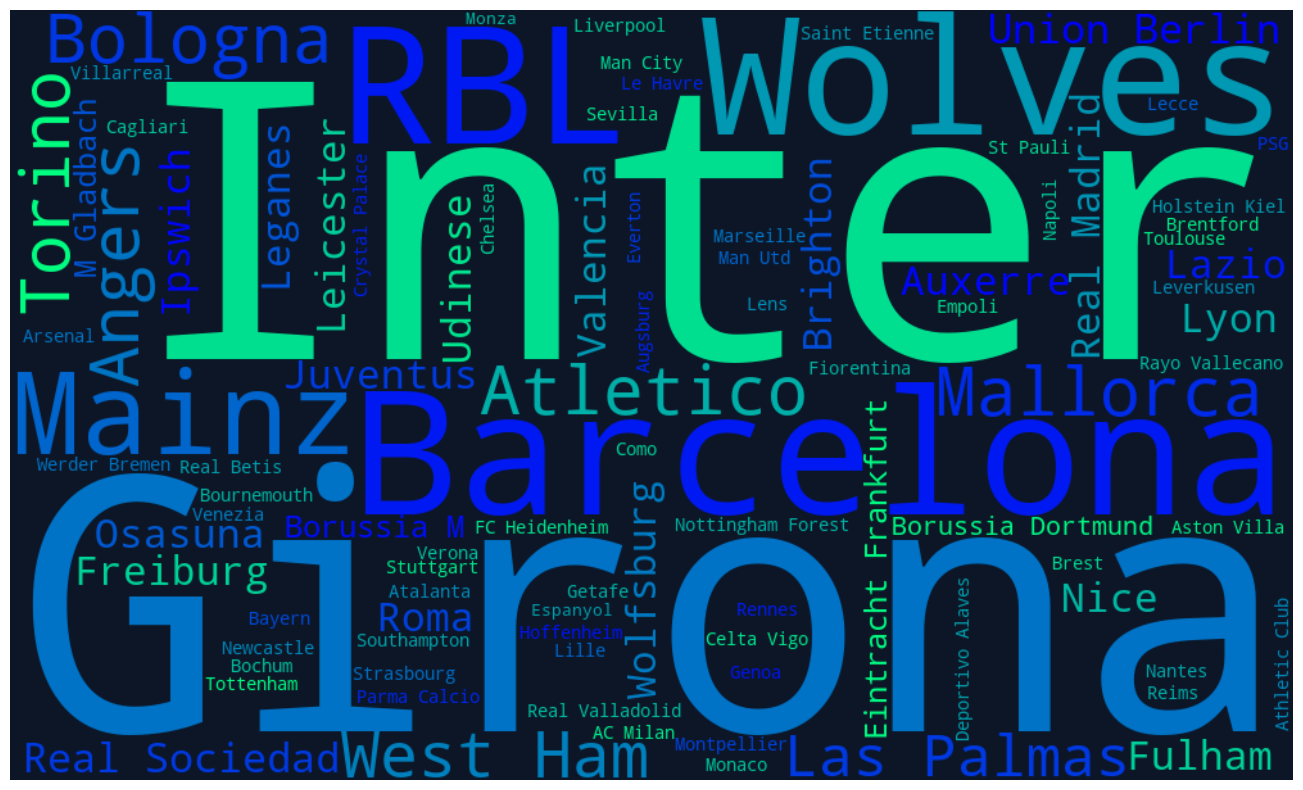

In [35]:
data3 = ",".join(df["Player Team"].astype(str))

wordcloud = WordCloud(
    width=1000,
    height=600
    ,background_color="#0d1627",
    colormap="winter"
).generate(data3)
plt.figure(figsize = (20,10))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")